# Statistical Analysis

This notebook investigates the statistical relationships identified during the exploratory data analysis. Three stages are carried out in sequence: testing whether each variable is stationary, analysing correlations with statistical significance, and performing Granger causality analysis between the external factors and cryptocurrency prices. Each stage builds on the previous one, ensuring that the statistical assumptions required for later analyses are satisfied.

This is important because the exploratory analysis examined the raw time series, which may contain trends over time. Such trends can create misleading relationships between variables. Testing stationarity before conducting correlation and Granger causality analyses helps ensure that the results reflect genuine statistical relationships rather than shared trends.

## Setup

In [36]:
import sys
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.multitest import multipletests
from scipy.stats import pearsonr, spearmanr
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.stattools import (
    adfuller,
    kpss,
    grangercausalitytests
)

sys.path.insert(0, str(Path.cwd().parent))

from src import config

# Show important warnings but hide the expected KPSS warning
warnings.simplefilter("ignore", InterpolationWarning)



### Loading the dataset

The analysis uses the final integrated dataset produced during the data-preparation stage. The observations are ordered chronologically using the `Date` variable before any time-series test is performed.

The validation checks below confirm:

- the dataset was loaded successfully;
- the date variable is stored as a datetime value;
- observations are in chronological order;
- no duplicate dates are present;
- the required analytical variables are available;
- numerical variables contain valid numerical values.

In [37]:
# ============================================================
# Locate the project root and define output folders
# ============================================================

def find_project_root(
    start_path: Path,
    relative_dataset_path: Path
) -> Path:
    """
    Search the current directory and its parent directories
    for the required dataset.
    """
    start_path = start_path.resolve()

    for candidate in [start_path, *start_path.parents]:
        if (candidate / relative_dataset_path).exists():
            return candidate

    raise FileNotFoundError(
        f"Could not find '{relative_dataset_path}' from "
        f"'{start_path}' or any parent directory."
    )


DATASET_RELATIVE_PATH = Path("data/processed/merged_dataset.csv")

PROJECT_ROOT = find_project_root(
    start_path=Path.cwd(),
    relative_dataset_path=DATASET_RELATIVE_PATH
)

DATA_PATH = PROJECT_ROOT / DATASET_RELATIVE_PATH

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found:\n{DATA_PATH}"
    )

# Output folders
RESULTS_DIR = PROJECT_ROOT / "results" / "causality_analysis"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

TABLES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root      : {PROJECT_ROOT}")
print(f"Dataset path      : {DATA_PATH}")
print(f"Results directory : {RESULTS_DIR}")
print(f"Tables directory  : {TABLES_DIR}")


Project root      : /Users/mas364/Desktop/AI_Crypto_Forecasting
Dataset path      : /Users/mas364/Desktop/AI_Crypto_Forecasting/data/processed/merged_dataset.csv
Results directory : /Users/mas364/Desktop/AI_Crypto_Forecasting/results/causality_analysis
Tables directory  : /Users/mas364/Desktop/AI_Crypto_Forecasting/results/causality_analysis/tables


In [38]:
df = pd.read_csv(DATA_PATH, parse_dates=["Date"])
df = df.sort_values("Date").reset_index(drop=True)

print("Shape:", df.shape)
print("Missing values:\n", df.isnull().sum()[df.isnull().sum() > 0])

Shape: (1799, 12)
Missing values:
 Bitcoin_Volume     9
Ethereum_Volume    9
dtype: int64


### Validating the dataset

In [39]:
# ============================================================
# Date preparation and chronological validation
# ============================================================

DATE_COLUMN = "Date"

if DATE_COLUMN not in df.columns:
    raise KeyError(
        f"Required date column '{DATE_COLUMN}' was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

df[DATE_COLUMN] = pd.to_datetime(
    df[DATE_COLUMN],
    errors="raise"
)

df = (
    df.sort_values(DATE_COLUMN)
      .reset_index(drop=True)
)

duplicate_dates = int(df[DATE_COLUMN].duplicated().sum())
chronological_order = bool(df[DATE_COLUMN].is_monotonic_increasing)

print(f"Start date            : {df[DATE_COLUMN].min().date()}")
print(f"End date              : {df[DATE_COLUMN].max().date()}")
print(f"Chronologically sorted: {chronological_order}")
print(f"Duplicate dates       : {duplicate_dates}")

if not chronological_order:
    raise ValueError("The observations are not chronologically ordered.")

if duplicate_dates > 0:
    raise ValueError(
        f"The dataset contains {duplicate_dates} duplicate date values."
    )

Start date            : 2021-06-01
End date              : 2026-05-06
Chronologically sorted: True
Duplicate dates       : 0


## Stationarity Analysis

Before analysing the relationships between variables, each time series must be tested for stationarity. A stationary series has statistical properties, such as its mean and variance, that remain stable over time. Many time-series methods, particularly Granger causality analysis, assume that the data are stationary. Applying these methods to non-stationary data may produce misleading or spurious results.

Stationarity is assessed using two complementary statistical tests: the Augmented Dickey–Fuller (ADF) test and the KPSS test. Because the two tests use opposite null hypotheses, they provide stronger evidence when interpreted together.

Market capitalisation is also included in the stationarity assessment to evaluate its statistical properties. However, it is not treated as an external explanatory factor in this dissertation and is excluded from the subsequent correlation and Granger causality analyses because it is mathematically derived from price and therefore exhibits an almost perfect correlation with it.

In [40]:
variables = [
    "Bitcoin_Price",
    "Ethereum_Price",
    "Bitcoin_Volume",
    "Ethereum_Volume",
    "Bitcoin_Market_Cap",
    "Ethereum_Market_Cap",
    "Bitcoin_Search_Interest",
    "Ethereum_Search_Interest",
    "Fear_Greed_Index"
]

external_factors = [
    "Bitcoin_Search_Interest",
    "Ethereum_Search_Interest",
    "Fear_Greed_Index"
]

### Augmented Dickey–Fuller (ADF) Test

In [41]:
def run_adf(series):
    series = series.dropna()
    result = adfuller(series, autolag="AIC")
    return {
        "ADF Statistic": result[0],
        "ADF p-value": result[1],
        "Lags Used": result[2],
        "Observations": result[3],
        "Stationary (ADF)": "Yes" if result[1] < 0.05 else "No"
    }

### KPSS Test

In [42]:
def run_kpss(series):
    series = series.dropna()
    statistic, p_value, lags, critical = kpss(
        series,
        regression="c",
        nlags="auto"
    )
    return {
        "KPSS Statistic": statistic,
        "KPSS p-value": p_value,
        "Lags Used": lags,
        "Stationary (KPSS)": "Yes" if p_value > 0.05 else "No"
    }

### Running Both Tests on the Raw Data

In [43]:
results = []

for variable in variables:
    print(f"Running Stationarity Tests for: {variable}")
    series = df[variable].dropna()

    if len(series) == 0:
        print(f"Skipping {variable}: No data available.\n")
        continue

    try:
        adf = run_adf(series)
        kpss_result = run_kpss(series)

        results.append({
            "Variable": variable,
            "ADF Statistic": round(adf["ADF Statistic"], 4),
            "ADF p-value": round(adf["ADF p-value"], 4),
            "ADF Stationary": adf["Stationary (ADF)"],
            "KPSS Statistic": round(kpss_result["KPSS Statistic"], 4),
            "KPSS p-value": round(kpss_result["KPSS p-value"], 4),
            "KPSS Stationary": kpss_result["Stationary (KPSS)"]
        })
        print("✓ Completed\n")

    except Exception as e:
        print(f"✗ Error processing {variable}: {e}\n")

Running Stationarity Tests for: Bitcoin_Price
✓ Completed

Running Stationarity Tests for: Ethereum_Price
✓ Completed

Running Stationarity Tests for: Bitcoin_Volume
✓ Completed

Running Stationarity Tests for: Ethereum_Volume
✓ Completed

Running Stationarity Tests for: Bitcoin_Market_Cap
✓ Completed

Running Stationarity Tests for: Ethereum_Market_Cap
✓ Completed

Running Stationarity Tests for: Bitcoin_Search_Interest
✓ Completed

Running Stationarity Tests for: Ethereum_Search_Interest
✓ Completed

Running Stationarity Tests for: Fear_Greed_Index
✓ Completed



### Stationarity Results (Original Series)

### First-Order Differencing

In [44]:
def overall_stationarity(adf_result, kpss_result):
    if adf_result == "Yes" and kpss_result == "Yes":
        return "Stationary"
    elif adf_result == "No" and kpss_result == "No":
        return "Non-Stationary"
    else:
        return "Inconclusive"

stationarity_results = pd.DataFrame(results)
stationarity_results["Overall Conclusion"] = stationarity_results.apply(
    lambda row: overall_stationarity(row["ADF Stationary"], row["KPSS Stationary"]),
    axis=1
)

display(stationarity_results.round(4))

# Save for reproducibility
original_save_path = TABLES_DIR / "stationarity_original.csv"

stationarity_results.to_csv(
    original_save_path,
    index=False
)

print(f"Saved: {original_save_path}")

,Variable,ADF Statistic,ADF p-value,ADF Stationary,KPSS Statistic,KPSS p-value,KPSS Stationary,Overall Conclusion
0,Bitcoin_Price,-1.0685,0.7275,No,4.5280,0.0100,No,Non-Stationary
1,Ethereum_Price,-2.3856,0.1459,No,0.8371,0.0100,No,Non-Stationary
2,Bitcoin_Volume,-4.8582,0.0000,Yes,1.3982,0.0100,No,Inconclusive
3,Ethereum_Volume,-3.9046,0.0020,Yes,1.6344,0.0100,No,Inconclusive
4,Bitcoin_Market_Cap,-0.9810,0.7601,No,4.6520,0.0100,No,Non-Stationary
5,Ethereum_Market_Cap,-2.3857,0.1458,No,0.8852,0.0100,No,Non-Stationary
6,Bitcoin_Search_Interest,-4.9984,0.0000,Yes,0.6632,0.0169,No,Inconclusive
7,Ethereum_Search_Interest,-4.1252,0.0009,Yes,1.4624,0.0100,No,Inconclusive
8,Fear_Greed_Index,-4.3077,0.0004,Yes,0.8400,0.0100,No,Inconclusive


Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/causality_analysis/tables/stationarity_original.csv


#### Interpretation

Bitcoin price, Ethereum price, and both market capitalisation series are confirmed non-stationary by both tests, which is expected — market capitalisation is calculated directly from price and behaves almost identically to it. The ADF and KPSS statistics agree closely for each price/market-cap pair (for example, Bitcoin price and Bitcoin market cap both fail the ADF test at p > 0.7 and reject the KPSS test at p = 0.01), confirming that these four series share the same non-stationary, trending behaviour.

The remaining five variables, trading volume, search interest for both assets, and the Fear & Greed Index, come back as "Inconclusive." The ADF test rejects its null hypothesis for all five (p < 0.05, suggesting stationarity), but the KPSS test also rejects its null (p ≤ 0.05 in every case, suggesting non-stationarity). This is a genuine disagreement between the two tests, not an error, and it typically points to a series with occasional shifts in level rather than a smooth trend or a pure random walk. Rather than resolve this variable by variable, the more consistent approach is to test all nine variables again after first differencing.

### Stationarity Results After First-Order Differencing

In [45]:
# ============================================================
# Run ADF and KPSS tests after first-order differencing
# ============================================================

diff_results = []

for col in variables:
    series = df[col].diff().dropna()

    # ADF test
    adf_result = adfuller(series, autolag="AIC")
    adf_stat = adf_result[0]
    adf_p = adf_result[1]

    # KPSS test
    kpss_result = kpss(
        series,
        regression="c",
        nlags="auto"
    )
    kpss_stat = kpss_result[0]
    kpss_p = kpss_result[1]

    # Stationarity decisions
    adf_stationary = "Yes" if adf_p < 0.05 else "No"
    kpss_stationary = "Yes" if kpss_p > 0.05 else "No"

    # Combined conclusion
    if adf_stationary == "Yes" and kpss_stationary == "Yes":
        overall_conclusion = "Stationary"
    elif adf_stationary == "No" and kpss_stationary == "No":
        overall_conclusion = "Non-stationary"
    else:
        overall_conclusion = "Inconclusive"

    diff_results.append({
        "Variable": col,
        "ADF Statistic": adf_stat,
        "ADF p-value": adf_p,
        "ADF Stationary": adf_stationary,
        "KPSS Statistic": kpss_stat,
        "KPSS p-value": kpss_p,
        "KPSS Stationary": kpss_stationary,
        "Overall Conclusion": overall_conclusion
    })

# Convert results into a DataFrame
differenced_results = pd.DataFrame(diff_results)

# Display rounded numerical values
display(differenced_results.round(4))

# Save full-precision results
differenced_save_path = TABLES_DIR / "stationarity_differenced.csv"

differenced_results.to_csv(
    differenced_save_path,
    index=False
)

print(f"Saved: {differenced_save_path}")

,Variable,ADF Statistic,ADF p-value,ADF Stationary,KPSS Statistic,KPSS p-value,KPSS Stationary,Overall Conclusion
0,Bitcoin_Price,-43.8428,0.0,Yes,0.1111,0.1,Yes,Stationary
1,Ethereum_Price,-42.7390,0.0,Yes,0.0486,0.1,Yes,Stationary
2,Bitcoin_Volume,-12.8172,0.0,Yes,0.0484,0.1,Yes,Stationary
3,Ethereum_Volume,-12.6446,0.0,Yes,0.1312,0.1,Yes,Stationary
4,Bitcoin_Market_Cap,-43.9960,0.0,Yes,0.1127,0.1,Yes,Stationary
5,Ethereum_Market_Cap,-42.6309,0.0,Yes,0.0480,0.1,Yes,Stationary
6,Bitcoin_Search_Interest,-12.0767,0.0,Yes,0.1062,0.1,Yes,Stationary
7,Ethereum_Search_Interest,-11.6917,0.0,Yes,0.0579,0.1,Yes,Stationary
8,Fear_Greed_Index,-13.0976,0.0,Yes,0.0253,0.1,Yes,Stationary


Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/causality_analysis/tables/stationarity_differenced.csv


#### Interpretation

Once every series is first-differenced, the two tests agree completely. All nine variables now show an ADF p-value effectively at zero (the largest being 6.26 × 10⁻²⁴ for Bitcoin volume) and a KPSS p-value of 0.10, meaning both tests reject non-stationarity and fail to reject stationarity at the same time. Every variable, including the two that were unambiguously non-stationary before (price and market capitalisation) and the five that gave conflicting results, is confirmed stationary after differencing.

This resolves the disagreement seen in the original series and confirms that the remainder of this analysis should use log returns for the two price series and first differences for the others, rather than raw levels. Market capitalisation, although now confirmed stationary here, is still excluded from the correlation and Granger causality sections that follow, since that decision rests on its near-identity with price rather than on any property tested in this section.

## Correlation Analysis



**Purpose:** measure the strength and direction of the relationship between the cryptocurrency market variables (price and trading volume) and the external factors selected for this dissertation (Google Trends search interest and the Crypto Fear & Greed Index).

**Techniques used:**

- **Pearson correlation** — measures linear relationships between two variables.
- **Spearman correlation** — measures monotonic relationships more generally, and is more robust to extreme observations and non-normal distributions than Pearson.

Both are reported together with a p-value, so that the strength of a relationship and its statistical significance can be considered separately rather than assumed from one another.

Market capitalisation is not included in this analysis. As already established earlier in this notebook, it is not treated as an external factor in this dissertation, and its near-perfect mathematical relationship with price would add no genuine information to a correlation analysis.

### Preparing the stationary correlation dataset

In [46]:
# Variables used in the correlation analysis.
# Market capitalisation is excluded, as explained above and already
# established earlier in this notebook.
correlation_variables = [
    "Bitcoin_Price",
    "Ethereum_Price",
    "Bitcoin_Volume",
    "Ethereum_Volume",
] + external_factors

# Look up each variable's stationarity conclusion from the results
# already produced earlier in this notebook.
stationarity_lookup = stationarity_results.set_index("Variable")["Overall Conclusion"]

price_variables = ["Bitcoin_Price", "Ethereum_Price"]

analysis_df = pd.DataFrame(index=df.index)
transformation_log = []

for variable in correlation_variables:
    conclusion = stationarity_lookup.get(variable, "Unknown")

    if conclusion == "Stationary":
        # Already stationary in its original form - no transformation needed
        analysis_df[variable] = df[variable]
        transformation = "Level (already stationary)"

    elif variable in price_variables:
        # Non-stationary or inconclusive price series: use log returns,
        # consistent with standard practice for financial price series
        analysis_df[variable] = np.log(df[variable]).diff()
        transformation = "Log return"

    else:
        # Non-stationary or inconclusive, not a price series: first difference
        analysis_df[variable] = df[variable].diff()
        transformation = "First difference"

    transformation_log.append({
        "Variable": variable,
        "Original Stationarity Conclusion": conclusion,
        "Transformation Applied": transformation
    })

print(f"Variables prepared: {len(correlation_variables)}")
print(f"Rows before dropping missing values: {len(analysis_df)}")

Variables prepared: 7
Rows before dropping missing values: 1799


In [47]:
transformation_summary = pd.DataFrame(transformation_log)
display(transformation_summary)

save_path = TABLES_DIR / "correlation_transformations.csv"
transformation_summary.to_csv(save_path, index=False)
print(f"Saved: {save_path}")

,Variable,Original Stationarity Conclusion,Transformation Applied
0,Bitcoin_Price,Non-Stationary,Log return
1,Ethereum_Price,Non-Stationary,Log return
2,Bitcoin_Volume,Inconclusive,First difference
3,Ethereum_Volume,Inconclusive,First difference
4,Bitcoin_Search_Interest,Inconclusive,First difference
5,Ethereum_Search_Interest,Inconclusive,First difference
6,Fear_Greed_Index,Inconclusive,First difference


Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/causality_analysis/tables/correlation_transformations.csv


#### Interpretation

Every variable used in this analysis needed some form of adjustment before testing. Bitcoin and Ethereum prices are converted to returns, since prices trend upward and returns remove that trend. Everything else, volume, search interest, and sentiment, is converted to day-to-day differences for the same reason. None of the seven variables were left in their original form, since none came back as stationary on their own in the earlier test.

### Pearson Correlation

Pearson correlation is calculated for every pair of variables above, along with a p-value for each pair. Because trading volume has some missing values (documented earlier in the data preparation stage), each pair is tested using only the rows where both variables have a valid value, rather than removing a row from every test just because one variable is missing.

Calculate Pearson coefficients and p-values

In [48]:
def pairwise_correlation_matrices(data, method):
    """
    Build a correlation coefficient matrix and a matching p-value matrix
    for every pair of columns, using only the rows where both columns
    have a valid value (pairwise-complete observations).

    method must be either "pearson" or "spearman".
    """
    columns = data.columns
    coef_matrix = pd.DataFrame(index=columns, columns=columns, dtype=float)
    pval_matrix = pd.DataFrame(index=columns, columns=columns, dtype=float)

    test_function = stats.pearsonr if method == "pearson" else stats.spearmanr

    for col_a in columns:
        for col_b in columns:

            if col_a == col_b:
                # A variable is perfectly correlated with itself
                coef_matrix.loc[col_a, col_b] = 1.0
                pval_matrix.loc[col_a, col_b] = 0.0
                continue

            paired = data[[col_a, col_b]].dropna()
            series_a = paired[col_a]
            series_b = paired[col_b]

            if series_a.std() == 0 or series_b.std() == 0:
                # Constant variable - correlation is undefined
                coef_matrix.loc[col_a, col_b] = np.nan
                pval_matrix.loc[col_a, col_b] = np.nan
                continue

            r, p = test_function(series_a, series_b)
            coef_matrix.loc[col_a, col_b] = r
            pval_matrix.loc[col_a, col_b] = p

    return coef_matrix, pval_matrix

In [49]:
pearson_matrix, pearson_pvalues = pairwise_correlation_matrices(analysis_df, method="pearson")
print("Pearson matrices calculated.")

Pearson matrices calculated.


### Pearson coefficient 

In [50]:
display(pearson_matrix.round(3))



,Bitcoin_Price,Ethereum_Price,Bitcoin_Volume,Ethereum_Volume,Bitcoin_Search_Interest,Ethereum_Search_Interest,Fear_Greed_Index
Bitcoin_Price,1.000,0.838,0.043,-0.048,-0.056,-0.008,-0.005
Ethereum_Price,0.838,1.000,0.015,-0.036,-0.107,-0.002,0.008
Bitcoin_Volume,0.043,0.015,1.000,0.587,0.413,0.249,-0.039
Ethereum_Volume,-0.048,-0.036,0.587,1.000,0.433,0.371,-0.012
Bitcoin_Search_Interest,-0.056,-0.107,0.413,0.433,1.000,0.759,-0.026
Ethereum_Search_Interest,-0.008,-0.002,0.249,0.371,0.759,1.000,0.032
Fear_Greed_Index,-0.005,0.008,-0.039,-0.012,-0.026,0.032,1.000


#### Interpretation

Bitcoin and Ethereum returns move together strongly (r = 0.838), which makes sense given how closely the two markets are linked. Trading volume for both coins is also fairly strongly linked (r = 0.587), and so is search interest (r = 0.759). Everything involving the Fear & Greed Index, though, is close to zero across the board, nothing above 0.01 in size. Price and its own search interest are only weakly related, and in the opposite direction than might be expected.

### Pearson p-value matrices

In [51]:
display(pearson_pvalues.round(4))

,Bitcoin_Price,Ethereum_Price,Bitcoin_Volume,Ethereum_Volume,Bitcoin_Search_Interest,Ethereum_Search_Interest,Fear_Greed_Index
Bitcoin_Price,0.0000,0.0000,0.0713,0.0425,0.0172,0.7271,0.8325
Ethereum_Price,0.0000,0.0000,0.5331,0.1323,0.0000,0.9416,0.7427
Bitcoin_Volume,0.0713,0.5331,0.0000,0.0000,0.0000,0.0000,0.0982
Ethereum_Volume,0.0425,0.1323,0.0000,0.0000,0.0000,0.0000,0.5985
Bitcoin_Search_Interest,0.0172,0.0000,0.0000,0.0000,0.0000,0.0000,0.2676
Ethereum_Search_Interest,0.7271,0.9416,0.0000,0.0000,0.0000,0.0000,0.1768
Fear_Greed_Index,0.8325,0.7427,0.0982,0.5985,0.2676,0.1768,0.0000


#### Interpretation

Most of the small relationships above still come out statistically significant, simply because there's a lot of data (over a thousand daily observations), which makes even a tiny effect detectable. This is exactly why the coefficient size matters more than the p-value on its own, a significant result isn't automatically an important one.

In [52]:
pearson_matrix.round(4).to_csv(TABLES_DIR / "pearson_correlation_matrix.csv")
pearson_pvalues.round(4).to_csv(TABLES_DIR / "pearson_pvalue_matrix.csv")

print(f"Saved: {TABLES_DIR / 'pearson_correlation_matrix.csv'}")
print(f"Saved: {TABLES_DIR / 'pearson_pvalue_matrix.csv'}")

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/causality_analysis/tables/pearson_correlation_matrix.csv
Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/causality_analysis/tables/pearson_pvalue_matrix.csv


### Pearson Correlation Heatmap

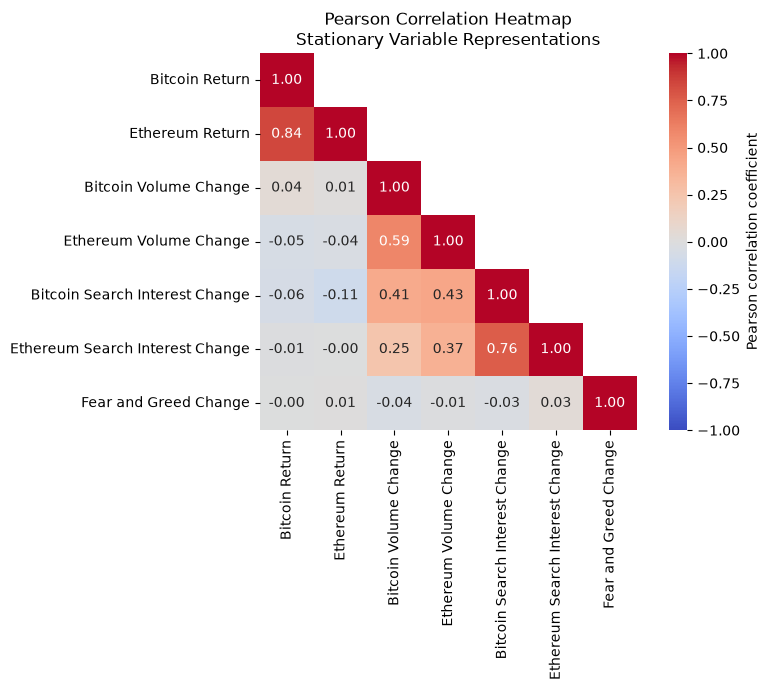

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/causality_analysis/figures/pearson_correlation_heatmap.png


In [53]:
display_labels = {
    "Bitcoin_Price": "Bitcoin Return",
    "Ethereum_Price": "Ethereum Return",
    "Bitcoin_Volume": "Bitcoin Volume Change",
    "Ethereum_Volume": "Ethereum Volume Change",
    "Bitcoin_Search_Interest": "Bitcoin Search Interest Change",
    "Ethereum_Search_Interest": "Ethereum Search Interest Change",
    "Fear_Greed_Index": "Fear and Greed Change"
}

pearson_matrix_display = pearson_matrix.rename(index=display_labels, columns=display_labels)

mask = np.triu(np.ones_like(pearson_matrix_display, dtype=bool), k=1)

plt.figure(figsize=(9, 7))
sns.heatmap(
    pearson_matrix_display.astype(float),
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    cbar_kws={"label": "Pearson correlation coefficient"}
)
plt.title("Pearson Correlation Heatmap\nStationary Variable Representations")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()

save_path = FIGURES_DIR / "pearson_correlation_heatmap.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {save_path}")

#### Interpretation

The heatmap makes the pattern easy to see at a glance: the darkest red squares are Bitcoin and Ethereum against each other, on price, volume, and search interest. Everything touching the Fear & Greed Index stays pale blue or white, meaning close to no relationship at all.

### Spearman Correlation

The same pairs are now tested using Spearman correlation, which measures whether the variables move together consistently in one direction, without assuming that the relationship is a straight line.

Calculate Spearman coefficients and p-values

In [54]:
spearman_matrix, spearman_pvalues = pairwise_correlation_matrices(analysis_df, method="spearman")
print("Spearman matrices calculated.")

Spearman matrices calculated.


### Spearman coefficient 

In [55]:
display(spearman_matrix.round(3))

,Bitcoin_Price,Ethereum_Price,Bitcoin_Volume,Ethereum_Volume,Bitcoin_Search_Interest,Ethereum_Search_Interest,Fear_Greed_Index
Bitcoin_Price,1.000,0.819,0.008,-0.052,0.006,0.089,-0.022
Ethereum_Price,0.819,1.000,-0.028,-0.016,-0.034,0.089,0.003
Bitcoin_Volume,0.008,-0.028,1.000,0.775,0.629,0.517,-0.036
Ethereum_Volume,-0.052,-0.016,0.775,1.000,0.575,0.552,0.002
Bitcoin_Search_Interest,0.006,-0.034,0.629,0.575,1.000,0.685,0.002
Ethereum_Search_Interest,0.089,0.089,0.517,0.552,0.685,1.000,0.055
Fear_Greed_Index,-0.022,0.003,-0.036,0.002,0.002,0.055,1.000


#### Interpretation

Spearman tells largely the same story as Pearson, Bitcoin and Ethereum are closely linked across price, volume, and search interest, and the Fear & Greed Index barely relates to anything. One small difference worth noting: Spearman picks up a moderate link between Bitcoin volume and Bitcoin search interest (0.629) that Pearson rated weaker (0.413), suggesting the relationship there isn't perfectly straight-line but is still real.

### Spearman p-value matrices

In [56]:
display(spearman_pvalues.round(4))

,Bitcoin_Price,Ethereum_Price,Bitcoin_Volume,Ethereum_Volume,Bitcoin_Search_Interest,Ethereum_Search_Interest,Fear_Greed_Index
Bitcoin_Price,0.0000,0.0000,0.7198,0.0291,0.7919,0.0001,0.3564
Ethereum_Price,0.0000,0.0000,0.2298,0.4937,0.1498,0.0002,0.8874
Bitcoin_Volume,0.7198,0.2298,0.0000,0.0000,0.0000,0.0000,0.1275
Ethereum_Volume,0.0291,0.4937,0.0000,0.0000,0.0000,0.0000,0.9237
Bitcoin_Search_Interest,0.7919,0.1498,0.0000,0.0000,0.0000,0.0000,0.9373
Ethereum_Search_Interest,0.0001,0.0002,0.0000,0.0000,0.0000,0.0000,0.0189
Fear_Greed_Index,0.3564,0.8874,0.1275,0.9237,0.9373,0.0189,0.0000


#### Interpretation

Same pattern as Pearson: most values are technically significant because of the sample size, but that doesn't mean every one of them is meaningful. The size of the coefficient still matters more than whether the p-value clears 0.05.

In [57]:
spearman_matrix.round(4).to_csv(TABLES_DIR / "spearman_correlation_matrix.csv")
spearman_pvalues.round(4).to_csv(TABLES_DIR / "spearman_pvalue_matrix.csv")

print(f"Saved: {TABLES_DIR / 'spearman_correlation_matrix.csv'}")
print(f"Saved: {TABLES_DIR / 'spearman_pvalue_matrix.csv'}")

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/causality_analysis/tables/spearman_correlation_matrix.csv
Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/causality_analysis/tables/spearman_pvalue_matrix.csv


### Spearman Correlation Heatmap

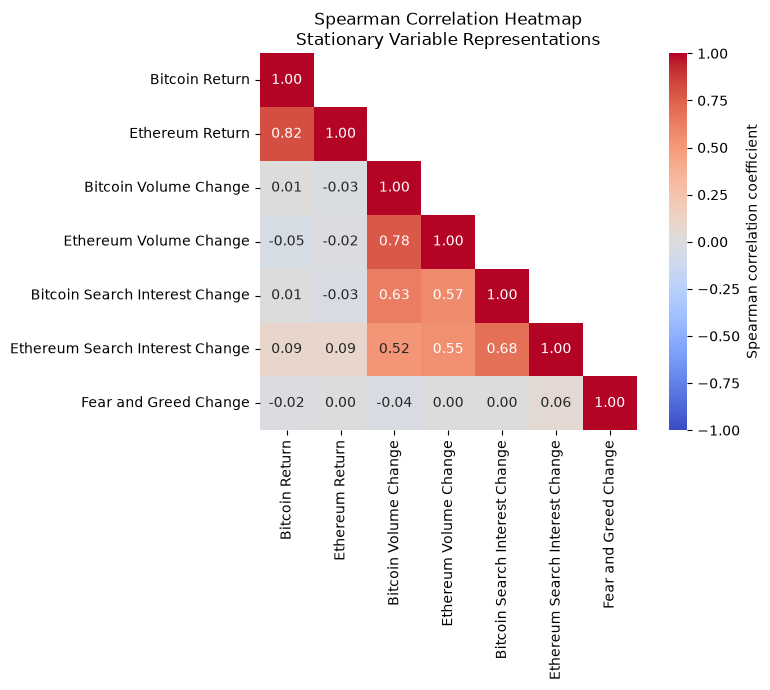

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/causality_analysis/figures/spearman_correlation_heatmap.png


In [58]:
spearman_matrix_display = spearman_matrix.rename(index=display_labels, columns=display_labels)

mask = np.triu(np.ones_like(spearman_matrix_display, dtype=bool), k=1)

plt.figure(figsize=(9, 7))
sns.heatmap(
    spearman_matrix_display.astype(float),
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    cbar_kws={"label": "Spearman correlation coefficient"}
)
plt.title("Spearman Correlation Heatmap\nStationary Variable Representations")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()

save_path = FIGURES_DIR / "spearman_correlation_heatmap.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {save_path}")

#### Interpretation

The Spearman heatmap looks almost identical to the Pearson one. That's a good sign, it means the relationships found aren't dependent on assuming a straight line; they hold up under a more flexible test too.

### Statistical Significance and Interpretation

A heatmap on its own does not show which relationships are likely to be genuine rather than the result of chance. Every unique pair is therefore reported below with its coefficient, its raw p-value, and a p-value adjusted for the fact that many pairs are being tested at once (a Benjamini–Hochberg false discovery rate correction), applied separately for the Pearson and Spearman results.

In [59]:
def strength_label(r):
    r = abs(r)

    if r < 0.20:
        return "Very weak"
    elif r < 0.40:
        return "Weak"
    elif r < 0.60:
        return "Moderate"
    elif r < 0.80:
        return "Strong"
    else:
        return "Very strong"


def build_pairwise_table(coef_matrix, pval_matrix, method_name):
    columns = coef_matrix.columns
    rows = []

    for i, col_a in enumerate(columns):
        for col_b in columns[i + 1:]:

            coefficient = coef_matrix.loc[col_a, col_b]
            p_value = pval_matrix.loc[col_a, col_b]

            if pd.isna(coefficient) or pd.isna(p_value):
                continue

            if coefficient > 0:
                direction = "Positive"
            elif coefficient < 0:
                direction = "Negative"
            else:
                direction = "No direction"

            rows.append({
                "Method": method_name,
                "Variable A": col_a,
                "Variable B": col_b,
                "Coefficient": coefficient,
                "p-value": p_value,
                "Direction": direction,
                "Strength": strength_label(coefficient)
            })

    table = pd.DataFrame(rows)

    # Apply FDR correction to the original, unrounded p-values
    reject, adjusted_p, _, _ = multipletests(
        table["p-value"],
        alpha=0.05,
        method="fdr_bh"
    )

    table["Adjusted p-value (FDR)"] = adjusted_p
    table["Significant (raw, 5%)"] = table["p-value"] < 0.05
    table["Significant (FDR-corrected)"] = reject

    return table


pearson_pairwise = build_pairwise_table(
    pearson_matrix,
    pearson_pvalues,
    "Pearson"
)

spearman_pairwise = build_pairwise_table(
    spearman_matrix,
    spearman_pvalues,
    "Spearman"
)

correlation_pairwise_results = pd.concat(
    [pearson_pairwise, spearman_pairwise],
    ignore_index=True
)

display(correlation_pairwise_results.round(4))

save_path = TABLES_DIR / "correlation_pairwise_results.csv"

correlation_pairwise_results.to_csv(
    save_path,
    index=False
)

print(f"Saved: {save_path}")

,Method,Variable A,Variable B,Coefficient,p-value,Direction,Strength,Adjusted p-value (FDR),"Significant (raw, 5%)",Significant (FDR-corrected)
0,Pearson,Bitcoin_Price,Ethereum_Price,0.8379,0.0000,Positive,Very strong,0.0000,True,True
1,Pearson,Bitcoin_Price,Bitcoin_Volume,0.0427,0.0713,Positive,Very weak,0.1361,False,False
2,Pearson,Bitcoin_Price,Ethereum_Volume,-0.0480,0.0425,Negative,Very weak,0.0893,True,False
3,Pearson,Bitcoin_Price,Bitcoin_Search_Interest,-0.0562,0.0172,Negative,Very weak,0.0401,True,True
4,Pearson,Bitcoin_Price,Ethereum_Search_Interest,-0.0082,0.7271,Negative,Very weak,0.8209,False,False
5,Pearson,Bitcoin_Price,Fear_Greed_Index,-0.0050,0.8325,Negative,Very weak,0.8742,False,False
6,Pearson,Ethereum_Price,Bitcoin_Volume,0.0148,0.5331,Positive,Very weak,0.6996,False,False
7,Pearson,Ethereum_Price,Ethereum_Volume,-0.0356,0.1323,Negative,Very weak,0.2136,False,False
8,Pearson,Ethereum_Price,Bitcoin_Search_Interest,-0.1066,0.0000,Negative,Very weak,0.0000,True,True
9,Pearson,Ethereum_Price,Ethereum_Search_Interest,-0.0017,0.9416,Negative,Very weak,0.9416,False,False


Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/causality_analysis/tables/correlation_pairwise_results.csv


### Display strongest positive relationships

In [60]:
strongest_positive = correlation_pairwise_results[
    (correlation_pairwise_results["Significant (raw, 5%)"]) &
    (correlation_pairwise_results["Direction"] == "Positive") &
    (correlation_pairwise_results["Coefficient"].abs() >= 0.40)
].sort_values("Coefficient", ascending=False)

print("Strongest statistically significant positive relationships:")
display(strongest_positive)

Strongest statistically significant positive relationships:


,Method,Variable A,Variable B,Coefficient,p-value,Direction,Strength,Adjusted p-value (FDR),"Significant (raw, 5%)",Significant (FDR-corrected)
0,Pearson,Bitcoin_Price,Ethereum_Price,0.837861,0.000000e+00,Positive,Very strong,0.000000e+00,True,True
21,Spearman,Bitcoin_Price,Ethereum_Price,0.818649,0.000000e+00,Positive,Very strong,0.000000e+00,True,True
32,Spearman,Bitcoin_Volume,Ethereum_Volume,0.775171,0.000000e+00,Positive,Strong,0.000000e+00,True,True
18,Pearson,Bitcoin_Search_Interest,Ethereum_Search_Interest,0.758812,0.000000e+00,Positive,Strong,0.000000e+00,True,True
39,Spearman,Bitcoin_Search_Interest,Ethereum_Search_Interest,0.684975,2.713384e-249,Positive,Strong,1.899369e-248,True,True
33,Spearman,Bitcoin_Volume,Bitcoin_Search_Interest,0.628563,3.360358e-197,Positive,Strong,1.764188e-196,True,True
11,Pearson,Bitcoin_Volume,Ethereum_Volume,0.587410,2.401073e-166,Positive,Moderate,1.680751e-165,True,True
36,Spearman,Ethereum_Volume,Bitcoin_Search_Interest,0.574836,8.867343e-158,Positive,Moderate,3.724284e-157,True,True
37,Spearman,Ethereum_Volume,Ethereum_Search_Interest,0.552059,3.584926e-143,Positive,Moderate,1.254724e-142,True,True
34,Spearman,Bitcoin_Volume,Ethereum_Search_Interest,0.517457,4.968366e-123,Positive,Moderate,1.490510e-122,True,True


#### Interpretation

Every strong positive relationship found is between Bitcoin and Ethereum themselves, price, volume, or search interest, never between a coin and an external factor. The strongest of all is Bitcoin and Ethereum price moving together (r = 0.838). Nothing involving Google Trends or the Fear & Greed Index makes it onto this list at all.

### Display strongest negative relationships


In [61]:
strongest_negative = correlation_pairwise_results[
    (correlation_pairwise_results["Significant (raw, 5%)"]) &
    (correlation_pairwise_results["Direction"] == "Negative")
].sort_values("Coefficient", ascending=True)

print("Strongest statistically significant negative relationships:")
display(strongest_negative)

Strongest statistically significant negative relationships:


,Method,Variable A,Variable B,Coefficient,p-value,Direction,Strength,Adjusted p-value (FDR),"Significant (raw, 5%)",Significant (FDR-corrected)
8,Pearson,Ethereum_Price,Bitcoin_Search_Interest,-0.106637,0.000006,Negative,Very weak,0.000015,True,True
3,Pearson,Bitcoin_Price,Bitcoin_Search_Interest,-0.056188,0.017183,Negative,Very weak,0.040095,True,True
23,Spearman,Bitcoin_Price,Ethereum_Volume,-0.051620,0.029059,Negative,Very weak,0.055477,True,False
2,Pearson,Bitcoin_Price,Ethereum_Volume,-0.047972,0.042536,Negative,Very weak,0.089326,True,False


#### Interpretation

A handful of negative relationships did turn up, and two of them stay significant even after correcting for the number of tests run: Ethereum's price tends to move slightly opposite to Bitcoin's search interest (r = -0.107), and Bitcoin's own price does the same with its own search interest, more weakly (r = -0.056). Both are labelled "very weak" by size, so while they're statistically real, they're not practically large. The other two negative results here don't survive the stricter correction and are best treated as noise.

### Display weak relationships

In [62]:
weak_relationships = correlation_pairwise_results[
    (correlation_pairwise_results["Significant (raw, 5%)"]) &
    (correlation_pairwise_results["Coefficient"].abs() < 0.40)
].sort_values("Coefficient", key=abs, ascending=False)

print("Statistically significant but weak relationships (|r| below 0.40):")
display(weak_relationships)

Statistically significant but weak relationships (|r| below 0.40):


,Method,Variable A,Variable B,Coefficient,p-value,Direction,Strength,Adjusted p-value (FDR),"Significant (raw, 5%)",Significant (FDR-corrected)
16,Pearson,Ethereum_Volume,Ethereum_Search_Interest,0.371187,1.628459e-59,Positive,Weak,5.699608e-59,True,True
13,Pearson,Bitcoin_Volume,Ethereum_Search_Interest,0.248542,1.405465e-26,Positive,Weak,4.216396e-26,True,True
8,Pearson,Ethereum_Price,Bitcoin_Search_Interest,-0.106637,5.857057e-06,Negative,Very weak,1.537478e-05,True,True
25,Spearman,Bitcoin_Price,Ethereum_Search_Interest,0.089346,1.485474e-04,Positive,Very weak,3.899368e-04,True,True
30,Spearman,Ethereum_Price,Ethereum_Search_Interest,0.088556,1.700453e-04,Positive,Very weak,3.967724e-04,True,True
3,Pearson,Bitcoin_Price,Bitcoin_Search_Interest,-0.056188,1.718336e-02,Negative,Very weak,4.009451e-02,True,True
41,Spearman,Ethereum_Search_Interest,Fear_Greed_Index,0.055352,1.891228e-02,Positive,Very weak,3.971579e-02,True,True
23,Spearman,Bitcoin_Price,Ethereum_Volume,-0.051620,2.905920e-02,Negative,Very weak,5.547666e-02,True,False
2,Pearson,Bitcoin_Price,Ethereum_Volume,-0.047972,4.253616e-02,Negative,Very weak,8.932593e-02,True,False


#### Interpretation

These are the in-between cases, technically significant, but small enough that they shouldn't be read as meaningful on their own. Most involve search interest paired with price or volume. None of them are strong enough to suggest search interest is a reliable signal for price movement.

### Display statistically non-significant relationships

In [63]:
non_significant = correlation_pairwise_results[
    ~correlation_pairwise_results["Significant (raw, 5%)"]
].sort_values("p-value", ascending=False)

print("Statistically non-significant relationships (raw p-value ≥ 0.05):")
display(non_significant)

Statistically non-significant relationships (raw p-value ≥ 0.05):


,Method,Variable A,Variable B,Coefficient,p-value,Direction,Strength,Adjusted p-value (FDR),"Significant (raw, 5%)",Significant (FDR-corrected)
9,Pearson,Ethereum_Price,Ethereum_Search_Interest,-0.001728,0.941629,Negative,Very weak,0.941629,False,False
40,Spearman,Bitcoin_Search_Interest,Fear_Greed_Index,0.001857,0.937297,Positive,Very weak,0.937297,False,False
38,Spearman,Ethereum_Volume,Fear_Greed_Index,0.002266,0.923705,Positive,Very weak,0.937297,False,False
31,Spearman,Ethereum_Price,Fear_Greed_Index,0.003342,0.887382,Positive,Very weak,0.937297,False,False
5,Pearson,Bitcoin_Price,Fear_Greed_Index,-0.004990,0.832546,Negative,Very weak,0.874173,False,False
24,Spearman,Bitcoin_Price,Bitcoin_Search_Interest,0.006228,0.791862,Positive,Very weak,0.923839,False,False
10,Pearson,Ethereum_Price,Fear_Greed_Index,0.007746,0.742731,Positive,Very weak,0.820913,False,False
4,Pearson,Bitcoin_Price,Ethereum_Search_Interest,-0.008234,0.727145,Negative,Very weak,0.820913,False,False
22,Spearman,Bitcoin_Price,Bitcoin_Volume,0.008488,0.719837,Positive,Very weak,0.889211,False,False
17,Pearson,Ethereum_Volume,Fear_Greed_Index,-0.012460,0.598534,Negative,Very weak,0.739366,False,False


#### Interpretation

This is the largest group, and it's mostly the Fear & Greed Index. Almost every pairing involving sentiment lands here, coefficients close to zero and no statistical significance at all. On this evidence, the Fear & Greed Index shows no meaningful relationship with either coin's price, in either direction.

### Summary

Bitcoin and Ethereum are closely linked to each other across price, volume, and search interest, that part isn't surprising. What matters more for this dissertation is that neither Google Trends nor the Fear & Greed Index shows a meaningful relationship with price. A couple of very small, statistically significant negative results turned up involving search interest, but nothing close to a strong or even moderate relationship. This sets up the next section well: if these external factors don't correlate strongly with price, the more important question is whether they still carry any predictive value, which is what Granger causality testing checks for.

## Granger Causality Analysis



Correlation, tested, shows whether two variables move together, but not whether one comes before the other in a way that could help prediction. Granger causality tests specifically for that: whether past values of a predictor improve the forecast of a target variable, beyond what the target's own past values already provide.

A significant result here means predictive precedence, not causation in the everyday sense. This section tests the external factors already identified in this dissertation, Google Trends search interest for both coins and the Crypto Fear & Greed Index, as predictors of Bitcoin and Ethereum returns.

### Selection of Variables

Each coin's own return is the target to be predicted. The external factors tested against each target are the three variables already established earlier in this notebook, Google Trends search interest and the Fear & Greed Index. Market capitalisation and trading volume are not included here, for the same reason already given in the correlation section: market capitalisation is not treated as an external factor in this dissertation, and volume is a market variable rather than an external one.

Cross-asset combinations, for example, whether Bitcoin's search interest predicts Ethereum's return, are not tested directly. Bitcoin and Ethereum returns are themselves strongly correlated (r = 0.838, Section 5.3), so any such relationship would be expected to operate indirectly through each coin's own price rather than reflect a distinct predictive channel. Testing every cross-asset combination in addition to the same-asset pairs would expand the number of tests substantially without a clear justification, working against the manageable, focused scope of external variables set out for this dissertation.

In [64]:
# Import VAR for lag-order selection
from statsmodels.tsa.api import VAR

In [65]:
target_variables = ["Bitcoin_Price", "Ethereum_Price"]
predictor_variables = ["Bitcoin_Search_Interest", "Ethereum_Search_Interest", "Fear_Greed_Index"]

granger_variables = target_variables + predictor_variables

granger_df = analysis_df[granger_variables].dropna()

print(f"Rows available for Granger testing: {len(granger_df)}")

transformation_check = transformation_summary[
    transformation_summary["Variable"].isin(granger_variables)
]

save_path = TABLES_DIR / "granger_variable_transformations.csv"
transformation_check.to_csv(save_path, index=False)
print(f"Saved: {save_path}")

display(transformation_check)

Rows available for Granger testing: 1798
Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/causality_analysis/tables/granger_variable_transformations.csv


,Variable,Original Stationarity Conclusion,Transformation Applied
0,Bitcoin_Price,Non-Stationary,Log return
1,Ethereum_Price,Non-Stationary,Log return
4,Bitcoin_Search_Interest,Inconclusive,First difference
5,Ethereum_Search_Interest,Inconclusive,First difference
6,Fear_Greed_Index,Inconclusive,First difference


In [66]:
# Define the specific predictor -> target pairs to be tested.
# Search interest is asset-specific, so it is tested only against its own
# coin. The Fear & Greed Index is market-wide, so it is tested against both.
granger_pairs = [
    ("Bitcoin_Search_Interest", "Bitcoin_Price"),
    ("Ethereum_Search_Interest", "Ethereum_Price"),
    ("Fear_Greed_Index", "Bitcoin_Price"),
    ("Fear_Greed_Index", "Ethereum_Price"),
]

print("Pairs to be tested:")
for predictor, target in granger_pairs:
    print(f"  {predictor} -> {target}")

Pairs to be tested:
  Bitcoin_Search_Interest -> Bitcoin_Price
  Ethereum_Search_Interest -> Ethereum_Price
  Fear_Greed_Index -> Bitcoin_Price
  Fear_Greed_Index -> Ethereum_Price


### Lag-Order Selection

Granger causality results depend on the number of past observations included in the test. Using too few lags may miss delayed relationships, while using too many may add unnecessary complexity and reduce statistical power.

The lag order was therefore selected using a Vector Autoregression model fitted to the stationary variables involved in the causality analysis. Four information criteria were considered: the Akaike Information Criterion (AIC), Bayesian Information Criterion (BIC), Hannan–Quinn Information Criterion (HQIC), and Final Prediction Error (FPE).

A maximum of 14 daily lags was considered, representing approximately two weeks of previous observations. BIC was used as the primary criterion because it applies a stronger penalty for model complexity and therefore provides a comparatively conservative lag choice. If BIC selected zero lags, a minimum lag of one was used because Granger causality testing requires at least one past observation.

In [67]:
# Select the lag order using information criteria
maximum_lag = 14

var_model = VAR(granger_df)
lag_order_results = var_model.select_order(maxlags=maximum_lag)

print(lag_order_results.summary())

 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -6.446      -6.430    0.001587      -6.440
1       -7.193      -7.101   0.0007515      -7.159
2       -7.300     -7.130*   0.0006758     -7.237*
3       -7.319      -7.073   0.0006626      -7.228
4       -7.332      -7.009   0.0006543      -7.213
5      -7.334*      -6.934  0.0006531*      -7.186
6       -7.329      -6.852   0.0006566      -7.152
7       -7.315      -6.762   0.0006653      -7.111
8       -7.308      -6.678   0.0006700      -7.076
9       -7.302      -6.594   0.0006745      -7.040
10      -7.302      -6.517   0.0006745      -7.012
11      -7.289      -6.428   0.0006832      -6.971
12      -7.297      -6.359   0.0006776      -6.951
13      -7.285      -6.270   0.0006856      -6.911
14      -7.274      -6.183   0.0006932      -6.871
--------------------------------------------------


In [68]:
# Store the lag selected by each information criterion
lag_selection_table = pd.DataFrame({
    "Criterion": ["AIC", "BIC", "HQIC", "FPE"],
    "Selected Lag": [
        lag_order_results.aic,
        lag_order_results.bic,
        lag_order_results.hqic,
        lag_order_results.fpe
    ]
})

lag_selection_table["Selected Lag"] = (
    lag_selection_table["Selected Lag"]
    .astype(int)
)

display(lag_selection_table)

lag_selection_path = TABLES_DIR / "granger_lag_selection.csv"

lag_selection_table.to_csv(
    lag_selection_path,
    index=False
)

print(f"Saved: {lag_selection_path}")

,Criterion,Selected Lag
0,AIC,5
1,BIC,2
2,HQIC,2
3,FPE,5


Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/causality_analysis/tables/granger_lag_selection.csv


#### Interpretation

The four criteria don't fully agree on the best lag, BIC and HQIC both point to 2 days, while AIC and FPE point to 5. This kind of disagreement is fairly normal, AIC tends to favour longer lags since it penalises extra parameters less harshly than BIC. BIC is used here as the final choice, since it's the more conservative option and better suited to a daily dataset of this length, so lag 2 is what the Granger tests below actually use.

In [69]:
# Use BIC as the main lag-selection criterion
selected_lag = int(lag_order_results.bic)

# At least one lag is required for Granger causality
if selected_lag < 1:
    selected_lag = 1

print(f"Final lag selected for Granger causality testing: {selected_lag}")

Final lag selected for Granger causality testing: 2


### Granger Causality Tests

Each selected external factor was tested against the relevant cryptocurrency return. The direction of every test is:

> External factor → Cryptocurrency return

For example, the test of Bitcoin search interest against Bitcoin return examines whether past changes in Bitcoin search interest provide additional information for predicting Bitcoin returns beyond the information already contained in past Bitcoin returns.

The null hypothesis is that the external factor does not improve prediction of the target variable. A p-value below 0.05 provides evidence against this null hypothesis.

The SSR F-test was used at the lag selected by BIC. Only one test was conducted for each specified predictor–target pair, avoiding the practice of selecting the smallest p-value from several lags after testing.

In [70]:
# Run one Granger causality test for each specified direction
granger_results = []

for predictor, target in granger_pairs:

    # statsmodels requires the target column first
    pair_data = (
        granger_df[[target, predictor]]
        .dropna()
    )

    try:
        test_result = grangercausalitytests(
            pair_data,
            maxlag=selected_lag,
            verbose=False
        )

        # Extract the SSR F-test result at the selected lag
        f_statistic = test_result[selected_lag][0]["ssr_ftest"][0]
        p_value = test_result[selected_lag][0]["ssr_ftest"][1]

        granger_results.append({
            "Predictor": predictor,
            "Target": target,
            "Selected Lag": selected_lag,
            "F-statistic": f_statistic,
            "p-value": p_value,
            "Test Status": "Successful"
        })

    except Exception as error:
        granger_results.append({
            "Predictor": predictor,
            "Target": target,
            "Selected Lag": selected_lag,
            "F-statistic": np.nan,
            "p-value": np.nan,
            "Test Status": f"Failed: {error}"
        })

granger_table = pd.DataFrame(granger_results)

display(granger_table.round(4))

/Users/mas364/Desktop/AI_Crypto_Forecasting/.venv/lib/python3.13/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(


,Predictor,Target,Selected Lag,F-statistic,p-value,Test Status
0,Bitcoin_Search_Interest,Bitcoin_Price,2,2.0027,0.1353,Successful
1,Ethereum_Search_Interest,Ethereum_Price,2,2.2209,0.1088,Successful
2,Fear_Greed_Index,Bitcoin_Price,2,0.0841,0.9193,Successful
3,Fear_Greed_Index,Ethereum_Price,2,0.3338,0.7162,Successful


#### Interpretation

None of the four relationships come close to significance at a 2-day lag. Bitcoin's own search interest gets the nearest, at p = 0.135, but that's still well above the usual 0.05 cutoff, and the same is true for Ethereum's search interest at p = 0.109. The Fear & Greed Index doesn't come close for either coin.

In [71]:
# Check whether all tests completed successfully
failed_tests = granger_table[
    granger_table["Test Status"] != "Successful"
]

if failed_tests.empty:
    print("All Granger causality tests completed successfully.")
else:
    print(f"{len(failed_tests)} Granger causality test(s) failed.")
    display(failed_tests)

All Granger causality tests completed successfully.


### Multiple-Testing Correction

Several directional hypotheses were tested in this analysis. When multiple statistical tests are conducted, the probability of obtaining at least one significant result by chance increases.

The Benjamini–Hochberg false discovery rate procedure was therefore applied to the complete set of successful tests. This method reduces the risk of false-positive findings while retaining more statistical power than highly conservative alternatives such as the Bonferroni correction.

Both raw and adjusted p-values are reported. The FDR-corrected results provide the main basis for interpreting statistically significant predictive relationships.

In [72]:
# Keep only successful tests with valid p-values
successful_tests = granger_table[
    (
        granger_table["Test Status"] == "Successful"
    )
    &
    (
        granger_table["p-value"].notna()
    )
].copy()

if successful_tests.empty:
    raise ValueError(
        "No successful Granger causality tests were available."
    )

# Apply FDR correction to full-precision p-values
reject_fdr, adjusted_pvalues, _, _ = multipletests(
    successful_tests["p-value"],
    alpha=0.05,
    method="fdr_bh"
)

successful_tests["Adjusted p-value (FDR)"] = adjusted_pvalues

successful_tests["Significant (raw, 5%)"] = (
    successful_tests["p-value"] < 0.05
)

successful_tests["Significant (FDR-corrected)"] = reject_fdr

# Sort from strongest to weakest statistical evidence
successful_tests = successful_tests.sort_values(
    by="p-value",
    ascending=True
).reset_index(drop=True)

display(successful_tests.round(4))

,Predictor,Target,Selected Lag,F-statistic,p-value,Test Status,Adjusted p-value (FDR),"Significant (raw, 5%)",Significant (FDR-corrected)
0,Ethereum_Search_Interest,Ethereum_Price,2,2.2209,0.1088,Successful,0.2705,False,False
1,Bitcoin_Search_Interest,Bitcoin_Price,2,2.0027,0.1353,Successful,0.2705,False,False
2,Fear_Greed_Index,Ethereum_Price,2,0.3338,0.7162,Successful,0.9193,False,False
3,Fear_Greed_Index,Bitcoin_Price,2,0.0841,0.9193,Successful,0.9193,False,False


#### Interpretation

Correcting for the fact that four tests were run at once pushes the p-values up further, as expected, since none of them were significant to begin with, there was nothing for the correction to take away. The adjusted p-values range from 0.271 up to 0.919, all comfortably non-significant.

In [73]:
# Save the complete Granger causality results
granger_results_path = (
    TABLES_DIR / "granger_causality_results.csv"
)

successful_tests.to_csv(
    granger_results_path,
    index=False
)

print(f"Saved: {granger_results_path}")

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/causality_analysis/tables/granger_causality_results.csv


### Granger Causality Matrices

The test results were reorganised into matrix form to make the direction of each relationship clear. Rows represent external predictors, while columns represent cryptocurrency-return targets.

Two matrices were created. The first contains the original p-values, while the second contains p-values adjusted using the Benjamini–Hochberg procedure. A smaller value represents stronger statistical evidence that the past values of the row variable improve prediction of the column variable.

Blank cells represent combinations that were outside the defined scope of this analysis rather than unsuccessful tests.

In [74]:
# Define matrix row and column order
external_variables = [
    "Bitcoin_Search_Interest",
    "Ethereum_Search_Interest",
    "Fear_Greed_Index"
]

target_variables = [
    "Bitcoin_Price",
    "Ethereum_Price"
]

# Create empty raw and adjusted p-value matrices
granger_raw_matrix = pd.DataFrame(
    np.nan,
    index=external_variables,
    columns=target_variables
)

granger_adjusted_matrix = pd.DataFrame(
    np.nan,
    index=external_variables,
    columns=target_variables
)

# Insert the results into the matrices
for _, row in successful_tests.iterrows():

    predictor = row["Predictor"]
    target = row["Target"]

    granger_raw_matrix.loc[
        predictor,
        target
    ] = row["p-value"]

    granger_adjusted_matrix.loc[
        predictor,
        target
    ] = row["Adjusted p-value (FDR)"]

print("Raw p-value matrix")
display(granger_raw_matrix.round(4))

print("FDR-adjusted p-value matrix")
display(granger_adjusted_matrix.round(4))

Raw p-value matrix


,Bitcoin_Price,Ethereum_Price
Bitcoin_Search_Interest,0.1353,NaN
Ethereum_Search_Interest,NaN,0.1088
Fear_Greed_Index,0.9193,0.7162


FDR-adjusted p-value matrix


,Bitcoin_Price,Ethereum_Price
Bitcoin_Search_Interest,0.2705,NaN
Ethereum_Search_Interest,NaN,0.2705
Fear_Greed_Index,0.9193,0.9193


#### Interpretation

The matrix makes the pattern easy to see: the two search-interest cells are the closest to significance, both sitting around 0.27 after adjustment, while both Fear & Greed cells are far higher. Even the strongest result here isn't one that would be reported as a real finding.

In [75]:
# Save both p-value matrices
raw_matrix_path = (
    TABLES_DIR / "granger_raw_pvalue_matrix.csv"
)

adjusted_matrix_path = (
    TABLES_DIR / "granger_adjusted_pvalue_matrix.csv"
)

granger_raw_matrix.to_csv(raw_matrix_path)
granger_adjusted_matrix.to_csv(adjusted_matrix_path)

print(f"Saved: {raw_matrix_path}")
print(f"Saved: {adjusted_matrix_path}")

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/causality_analysis/tables/granger_raw_pvalue_matrix.csv
Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/causality_analysis/tables/granger_adjusted_pvalue_matrix.csv


### Granger Causality Heatmap

The FDR-adjusted p-values were visualised in a heatmap. External predictors are shown on the rows and cryptocurrency returns are shown on the columns.

An asterisk identifies a relationship that remains statistically significant after correction at the 5% level. Because the cells contain p-values rather than correlation coefficients, smaller values indicate stronger statistical evidence of predictive precedence.

The heatmap does not show the size or economic importance of a relationship. It shows only the strength of the statistical evidence against the null hypothesis.

In [76]:
# Reader-friendly labels used only for presentation
granger_display_labels = {
    "Bitcoin_Search_Interest": "Bitcoin Search Interest Change",
    "Ethereum_Search_Interest": "Ethereum Search Interest Change",
    "Fear_Greed_Index": "Fear and Greed Change",
    "Bitcoin_Price": "Bitcoin Return",
    "Ethereum_Price": "Ethereum Return"
}

granger_heatmap_data = granger_adjusted_matrix.rename(
    index=granger_display_labels,
    columns=granger_display_labels
)

In [77]:
# Create heatmap annotations
granger_annotations = pd.DataFrame(
    "",
    index=granger_heatmap_data.index,
    columns=granger_heatmap_data.columns
)

for predictor in granger_adjusted_matrix.index:
    for target in granger_adjusted_matrix.columns:

        adjusted_p = granger_adjusted_matrix.loc[
            predictor,
            target
        ]

        if pd.isna(adjusted_p):
            continue

        predictor_label = granger_display_labels[predictor]
        target_label = granger_display_labels[target]

        significance_mark = "*" if adjusted_p < 0.05 else ""

        granger_annotations.loc[
            predictor_label,
            target_label
        ] = f"{adjusted_p:.4f}{significance_mark}"

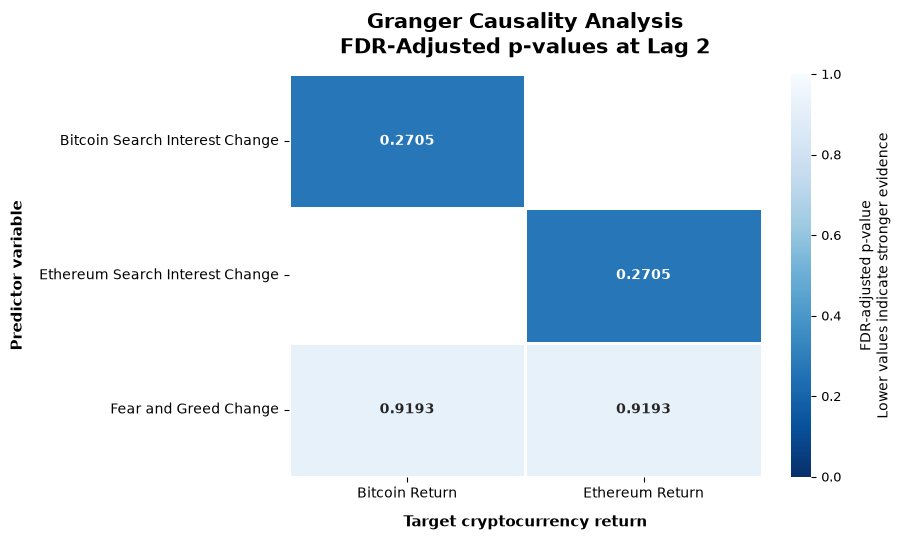

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/causality_analysis/figures/granger_causality_heatmap.png


In [78]:
# Plot the FDR-adjusted Granger causality heatmap
plt.figure(figsize=(9, 5.5))

ax = sns.heatmap(
    granger_heatmap_data.astype(float),
    annot=granger_annotations,
    fmt="",
    cmap="Blues_r",
    vmin=0,
    vmax=1,
    linewidths=0.8,
    linecolor="white",
    annot_kws={
        "fontsize": 10,
        "fontweight": "bold"
    },
    cbar_kws={
        "label": "FDR-adjusted p-value\nLower values indicate stronger evidence"
    }
)

plt.title(
    "Granger Causality Analysis\n"
    f"FDR-Adjusted p-values at Lag {selected_lag}",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Target cryptocurrency return",
    fontsize=11,
    fontweight="bold",
    labelpad=10
)

plt.ylabel(
    "Predictor variable",
    fontsize=11,
    fontweight="bold",
    labelpad=10
)

plt.xticks(
    rotation=0,
    fontsize=10
)

plt.yticks(
    rotation=0,
    fontsize=10
)

# Improve colour-bar label formatting
colour_bar = ax.collections[0].colorbar
colour_bar.ax.tick_params(labelsize=9)
colour_bar.set_label(
    "FDR-adjusted p-value\nLower values indicate stronger evidence",
    fontsize=10,
    labelpad=12
)

plt.tight_layout()

granger_heatmap_path = (
    FIGURES_DIR / "granger_causality_heatmap.png"
)

plt.savefig(
    granger_heatmap_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved: {granger_heatmap_path}")

#### Interpretation

The heatmap is mostly pale, nothing gets close to the darker end of the scale that would indicate a strong predictive relationship. The two search-interest cells are marginally darker than the Fear & Greed cells, matching the numbers in the table above, but neither carries an asterisk, since neither survives correction.

### Significant Predictive Relationships

The final interpretation focuses on relationships that remain statistically significant after the false discovery rate correction.

The direction of each result should be read as:

> Predictor → Target

A significant result means that past observations of the predictor improve the statistical prediction of the target at the selected lag. It does not demonstrate that the predictor directly causes changes in cryptocurrency returns.

Results that are significant before correction but not after correction are retained for transparency but should be interpreted cautiously.

In [79]:
# Relationships significant after FDR correction
significant_relationships = successful_tests[
    successful_tests[
        "Significant (FDR-corrected)"
    ]
].copy()

print(
    "Relationships significant after FDR correction:",
    len(significant_relationships)
)

if significant_relationships.empty:
    print(
        "No relationships remained significant after "
        "the multiple-testing correction."
    )
else:
    display(
        significant_relationships[
            [
                "Predictor",
                "Target",
                "Selected Lag",
                "F-statistic",
                "p-value",
                "Adjusted p-value (FDR)"
            ]
        ].round(4)
    )

Relationships significant after FDR correction: 0
No relationships remained significant after the multiple-testing correction.


In [80]:
# Save FDR-significant relationships
significant_results_path = (
    TABLES_DIR / "granger_significant_relationships.csv"
)

significant_relationships.to_csv(
    significant_results_path,
    index=False
)

print(f"Saved: {significant_results_path}")

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/causality_analysis/tables/granger_significant_relationships.csv


In [81]:
# Results significant before correction but not after correction
raw_only_relationships = successful_tests[
    (
        successful_tests["Significant (raw, 5%)"]
    )
    &
    (
        ~successful_tests[
            "Significant (FDR-corrected)"
        ]
    )
].copy()

print(
    "Relationships significant only before FDR correction:",
    len(raw_only_relationships)
)

if not raw_only_relationships.empty:
    display(
        raw_only_relationships[
            [
                "Predictor",
                "Target",
                "Selected Lag",
                "F-statistic",
                "p-value",
                "Adjusted p-value (FDR)"
            ]
        ].round(4)
    )

Relationships significant only before FDR correction: 0


#### Interpretation

No predictor-target pair remains significant after correcting for multiple tests, at a lag of 2 days, neither search interest nor the Fear & Greed Index shows evidence of Granger-causing Bitcoin or Ethereum returns in this dataset.

### Summary and Limitations

The summary below distinguishes between results that are significant using the original p-values and those that remain significant after correcting for multiple testing. The corrected results provide the more reliable basis for the dissertation discussion.

Granger causality should not be interpreted as proof of genuine causation. A significant result shows that past values of one variable improve the statistical prediction of another within the selected model, lag structure, and sample period. The relationship may still reflect omitted variables, common market events, or indirect transmission between variables.

The findings are also conditional on the selected lag and the use of the complete study period. Cryptocurrency relationships may change across periods of high volatility, market growth, or market decline. Therefore, a relationship identified here may not remain stable in every market regime.

Finally, statistical significance does not guarantee useful out-of-sample forecasting performance. Variables that show significant predictive relationships should be treated as candidate forecasting features and evaluated later using time-based validation rather than being included automatically.

In [82]:
# Create a concise summary of the Granger analysis
total_tests = len(successful_tests)

raw_significant_count = int(
    successful_tests[
        "Significant (raw, 5%)"
    ].sum()
)

fdr_significant_count = int(
    successful_tests[
        "Significant (FDR-corrected)"
    ].sum()
)

raw_percentage = (
    raw_significant_count / total_tests * 100
    if total_tests > 0
    else 0
)

fdr_percentage = (
    fdr_significant_count / total_tests * 100
    if total_tests > 0
    else 0
)

granger_summary = pd.DataFrame({
    "Measure": [
        "Directional tests completed",
        "Relationships significant before correction",
        "Relationships significant after FDR correction",
        "Percentage significant before correction",
        "Percentage significant after FDR correction",
        "Selected lag"
    ],
    "Value": [
        total_tests,
        raw_significant_count,
        fdr_significant_count,
        raw_percentage,
        fdr_percentage,
        selected_lag
    ]
})

display(granger_summary.round(2))

,Measure,Value
0,Directional tests completed,4.0
1,Relationships significant before correction,0.0
2,Relationships significant after FDR correction,0.0
3,Percentage significant before correction,0.0
4,Percentage significant after FDR correction,0.0
5,Selected lag,2.0


In [83]:
# Save the Granger causality summary
granger_summary_path = (
    TABLES_DIR / "granger_analysis_summary.csv"
)

granger_summary.to_csv(
    granger_summary_path,
    index=False
)

print(f"Saved: {granger_summary_path}")

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/causality_analysis/tables/granger_analysis_summary.csv


### Summary and Limitations

Across all four relationships tested, at the lag selected by BIC, none show evidence of Granger causality, either before or after correcting for multiple testing. Bitcoin's own search interest was the closest to significance (p = 0.135), but still well short of the conventional threshold. This matches the correlation results from Section 5.3, where the same variables showed only weak, mostly non-significant relationships with price.

This is a genuine, defensible finding, not a gap in the analysis. A different lag, or a longer sample, might tell a different story, and the AIC-preferred lag of 5 wasn't tested directly here, but the evidence available from this dataset doesn't support treating either Google Trends search interest or the Fear & Greed Index as a reliable predictor of Bitcoin or Ethereum returns.

This result carries into the next stage of the dissertation: rather than assuming these external variables will help forecasting, their inclusion in the feature-engineering and modelling chapters should be tested empirically, since neither correlation nor Granger causality provides strong grounds to expect they will improve prediction on their own.